# **Analyzing VinUni Building Detection Using YOLOv8 Segmentation**
**COMP4040 – Data Mining and Big Data Analytics — Final Milestone**

**Team Members:**
- Trinh Tuan Hung - V202401654
- Tran Thi Quynh Anh - V202301170

**Contributions:**

- Trinh Tuan Hung:
  - Designed and implemented the improved frame extraction pipeline, including blur detection to automatically filter low-quality frames
  - Configured and ran all four YOLOv8 segmentation training experiments (baseline, V2, V3, V4) on Google Colab
  - Implemented hyperparameter tuning across all model versions including learning rate, mixup, early stopping, and augmentation parameters
  - Conducted the confidence threshold analysis on V2 to investigate the precision-recall tradeoff
  - Developed the custom video inference pipeline with colored segmentation masks (red/blue) for visual model comparison
  - Evaluated all models using precision, recall, mAP@50, and mAP@50-95 metrics
  - Saved and organized trained model weights to Google Drive for deployment

- Tran Thi Quynh Anh:
  - Planned and recorded 12 new videos of Building K across two times of day (morning and dusk), four viewpoints, varying distances, and occlusion scenarios
  - Annotated all new images in Roboflow using polygon segmentation masks
  - Categorized each image across five tag dimensions: lighting condition, building visibility, camera side, occlusion, and rotation
  - Managed dataset versioning in Roboflow including augmentation configuration and dataset split rebalancing from 82/12/6 to 75/15/10
  - Performed quality checking on auto-annotated images and manually corrected imprecise masks
  - Contributed to report writing, results interpretation, and analysis of dataset distribution

In [10]:
# Environment Setup
"""
Google Drive is mounted to provide persistent access to the dataset,
trained model weights, and output files across Colab sessions.
"""
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

# **Introduction**
This is the final milestone for the building detection and segmentation project at the VinUniversity campus. In Milestone 1, we tried to set up a YOLOv8 nano segmentation model on top of 290 annotated images of Building K from the VinUniversity campus to achieve building detection and segmentation. The results showed a recall of 50.28% and an mAP@50 of 0.5924. This Milestone 2 aims to address two major limitations, i.e., lack of diversity in the dataset used for training the model and suboptimal configuration of the model. We collected a new dataset, trained four different models and compared them. The two best models are then demonstrated on a real video stream for demonstration purposes.

# **1. New Building K Dataset**

This new data-set is substantially larger in terms of both data size and data diversity compared to the data used for Milestone 1. While Milestone 1 had 290 images (total of 512 after all possible augmentation steps) that were all taken at one time of day, in the middle of the day, for this final milestone, 12 new videos of Building K were shot at two different times of day: morning and dusk. Each time of day was shot from 4 different viewpoints: front, side-left, side-right, and back. Also, shots were taken from a variety of distances to the building as well as shots with the subject partially occluded by trees, by vehicles driving down the lane in front of the building, and by pedestrians walking in front of the building.

The frames from the above videos were then extracted at the rate of 1 frame per second. The extracted frames were then run through the blur detection to discard the bad quality of the frames. The frames were then annotated in the Roboflow using polygon segmentation masks. Each of the images were then tagged with 5 descriptive fields. These fields were: the lighting condition, building visibility, camera side, occlusion and rotation. Combining the above with the original images from Milestone 1, we have a total of 579 images that have been annotated. These images then were run through 3x augmentation and rebalanced to a 75/15/10 training/validation/test split. This resulted in 1,294 images for training, 87 images for validation, and 58 images for testing.

In [ ]:
# Dataset Download
"""
The required libraries are installed: Ultralytics for YOLOv8 training and inference, and Roboflow for dataset management.
The annotated Building K dataset (Version 2) is downloaded directly from Roboflow in YOLOv8 segmentation format.
Version 2 contains 579 manually annotated images expanded to 1,439 images after applying 3x augmentation, split across train, validation, and test sets at a 75/15/10 ratio.
"""
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="YOUR_API_KEY") # hidden for confidential :D
project = rf.workspace("tuan-trinh-bfldh").project("vinuni_buildings_dataset")
version = project.version(2)
dataset = version.download("yolov8")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.2/249.2 kB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 91.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 151.9 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.92
    Uninstalling opencv-python-headless-4.13.0.92:
      Successfully uninstalled opencv-python-headless-4.13.0.92
  Attempting uninstall: idna
    Found existing installation: idna 3.18
    Uninstalling idna-3.18:
      Successfully uninstalled idna-3.18
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to VinUni_buildings_dataset-2 in yolov8:: 100%|██████████| 2883/2883 [00:00<00:00, 6753.18it/s]


In [ ]:
# Dataset confirmation
import os

data_yaml = dataset.location + "/data.yaml"

print(f"Dataset location: {dataset.location}")
print(f"Train images: {len(os.listdir(dataset.location + '/train/images'))}")
print(f"Valid images: {len(os.listdir(dataset.location + '/valid/images'))}")
print(f"Test images : {len(os.listdir(dataset.location + '/test/images'))}")
print(f"data.yaml exists: {os.path.exists(data_yaml)}")

Dataset location: /content/VinUni_buildings_dataset-2
Train images: 1294
Valid images: 87
Test images : 58
data.yaml exists: True


## **1.1 Image Categorization**

For every image within the dataset, the images have been manually tagged across 5 dimensions.

- **Lighting condition**: We captured images of buildings throughout the day, from morning (421 images) until dusk (176 images). For the rest of the images we simply reused the images from Milestone 1 which were all taken on a midday day like this.

- **Building visibility**: Images were tagged as either partial (567 images) or full (10 images) where the whole building is visible.

- **Camera side**: The side of the building in view of the camera: front (220 images), side-left (140 images), side-right (135 images), back (86 images). As expected, most of the images are taken from the front of the main entrance of the building, which is the most accessible side.

- **Occlusion**: 386 images of buildings are partially occluded by objects such as trees, vehicles, etc. which are partially in front of the building facade.

- **Rotation**: 20 images were taken at non-normal viewing angles (e.g. tilted) to test the models robustness to such viewing angles.
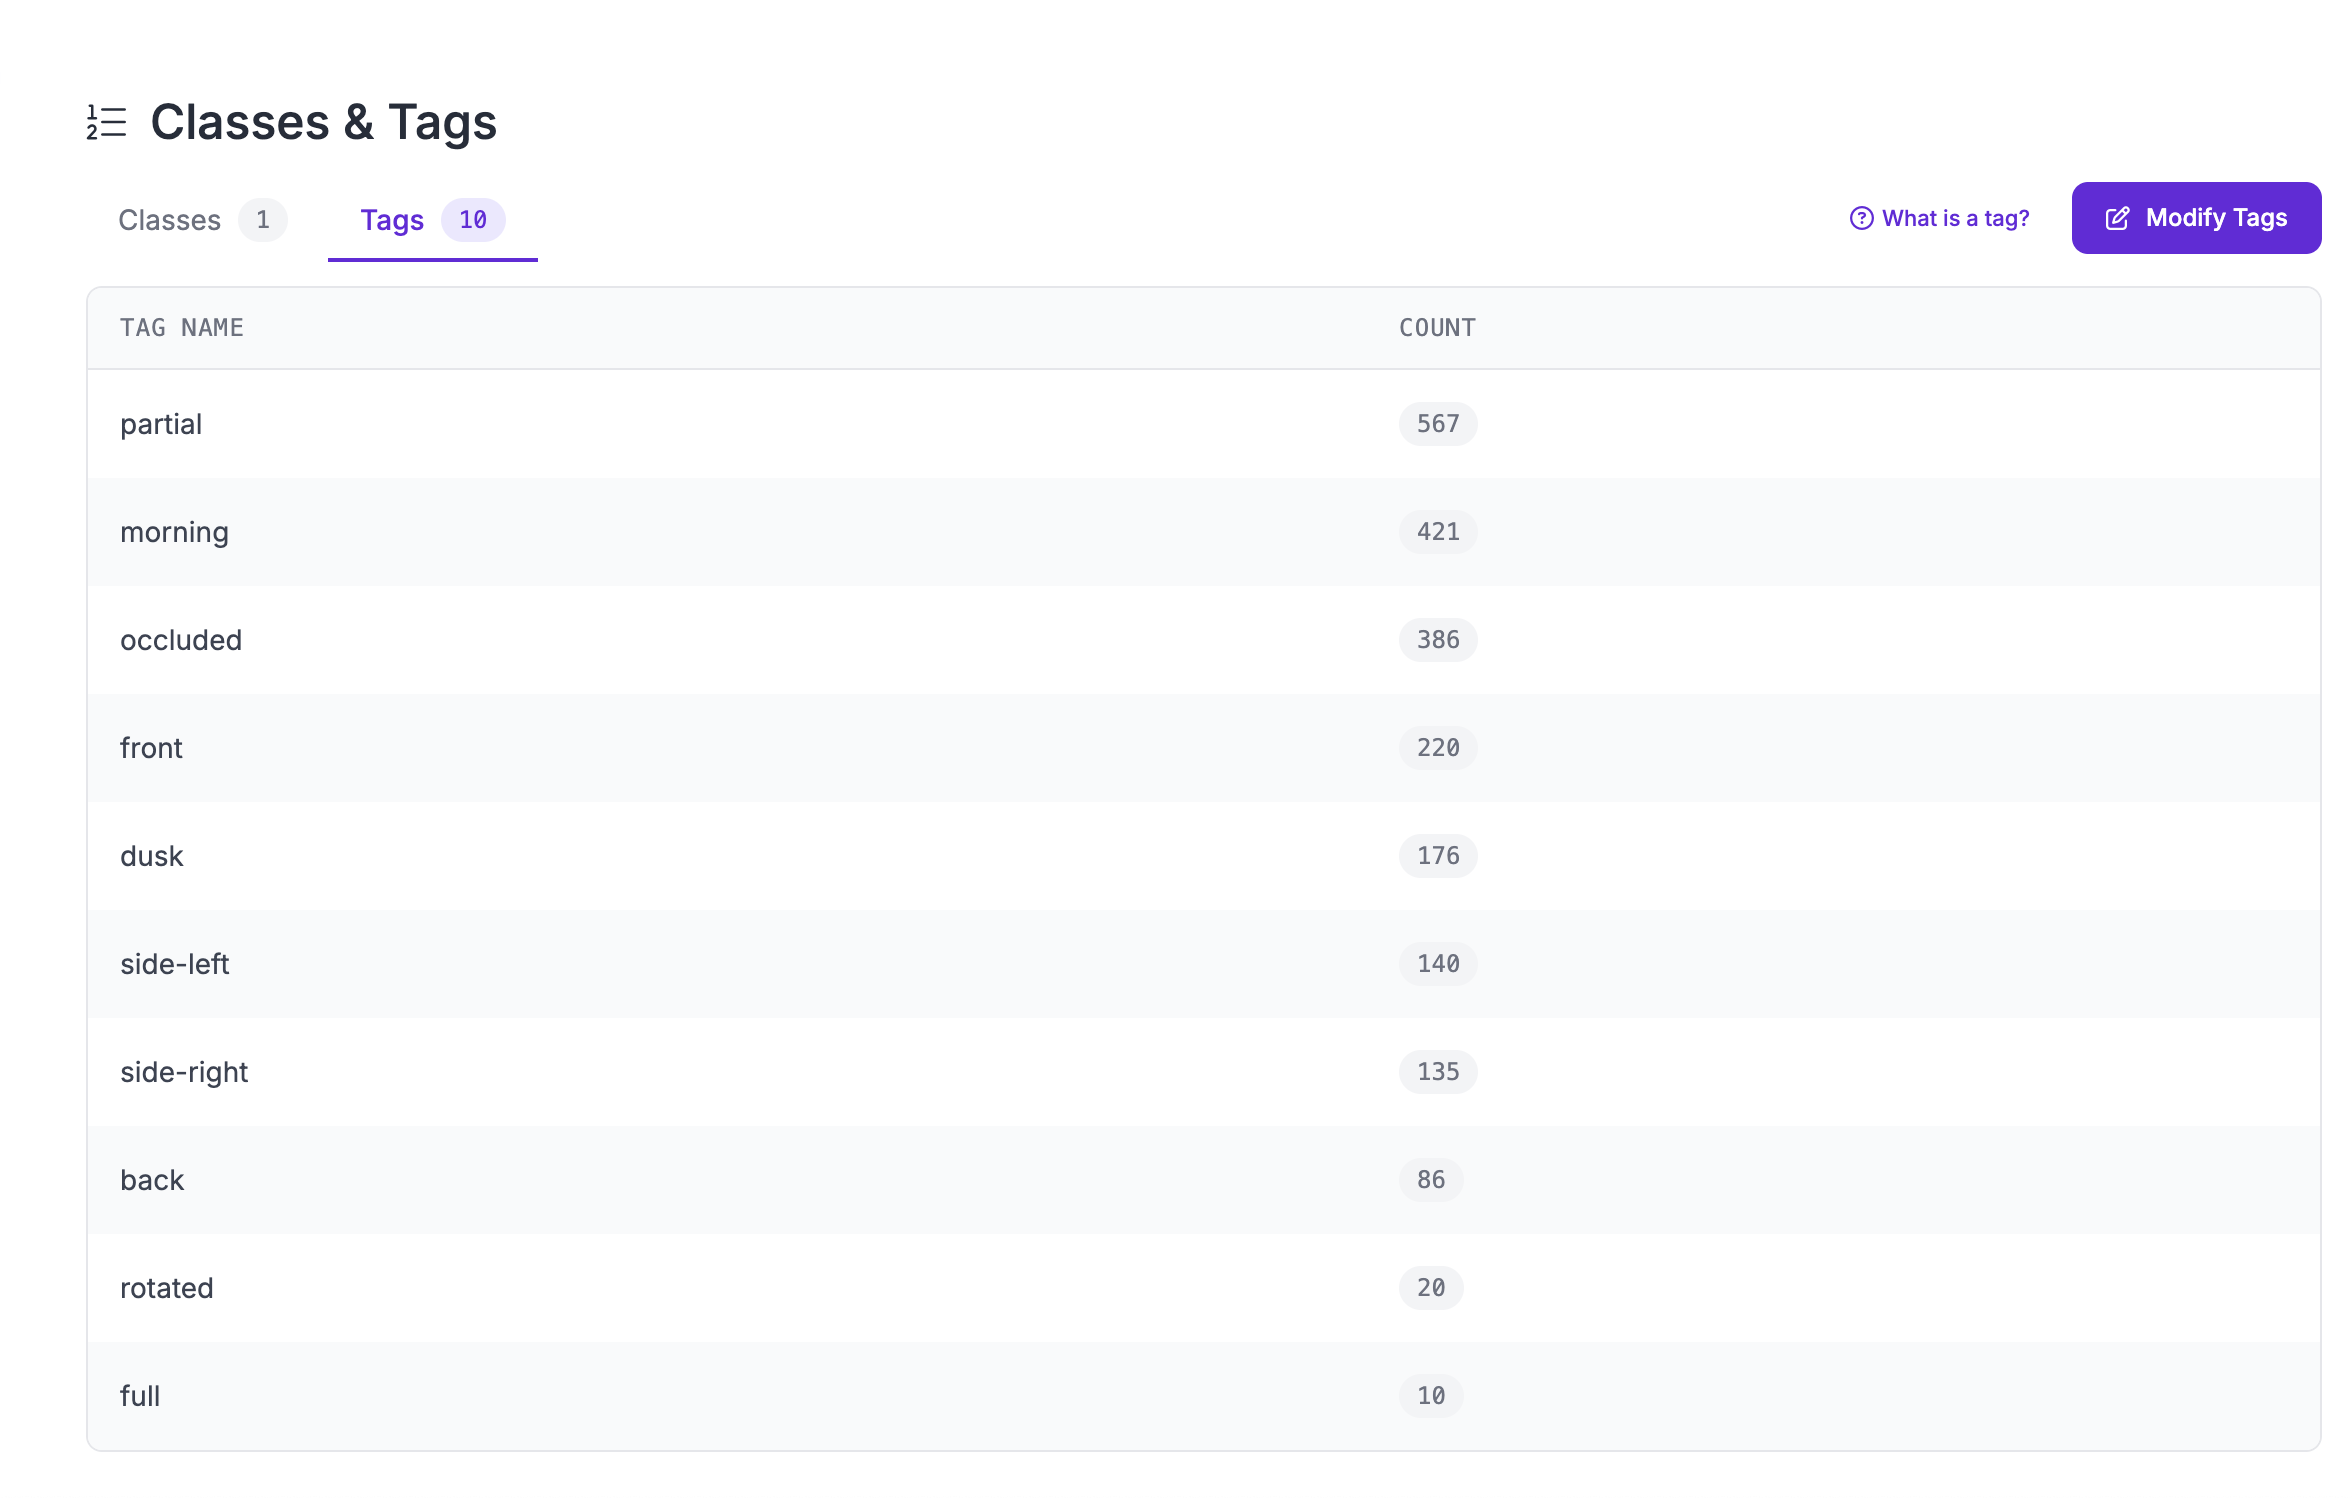



## **1.2 Dataset Composition**

The complete dataset consists of 579 images that have been annotated for the respective categories. After having applied 3x augmentation in Roboflow (grayscale & brightness variation) the training set now consists of 1,294 images in total. The dataset is split as follows for testing and validation:

- **Train:** 1,294 images (75%)
- **Validation:** 87 images (15%)
- **Test:** 58 images (10%)

This rebalances the original 82/12/6 split out to have suitable sized validation and test sets to ensure that reliable evaluation statistics are available.

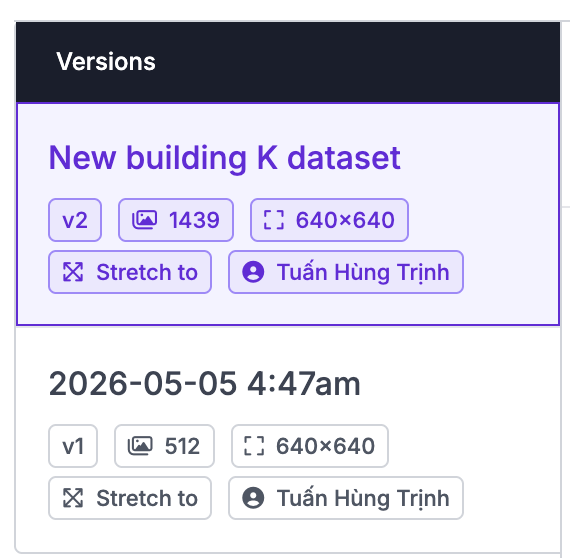

## **1.3 Data Augmentation**

In order to enhance the size of the training dataset and increase robustness of the model the following 3 techniques have been implemented using Roboflow.

- **Outputs per training example:** each original image is used to generate 2 different augmented images. So instead of using all 579 images from the data set (before filtering and splitting), a total of 1,439 images are used for training.
- **Grayscale (25% of images):** we use this augmentation to turn a quarter of the images in the training set to grayscale which forces the model to recognize Building K based on the shape/structure of the building as opposed to color.
- **Brightness variation (−25% to +25%):** This function is used to make the model more robust to changes in light intensity that occur during the day from morning over to midday and in the evening.

The 90° rotation augmentation that was used in Milestone 1 was not used in this Milestone. The reason for this is that for images of buildings such as this, images that are rotated by 90° or upside-down are not realistic and would not normally occur in real life.
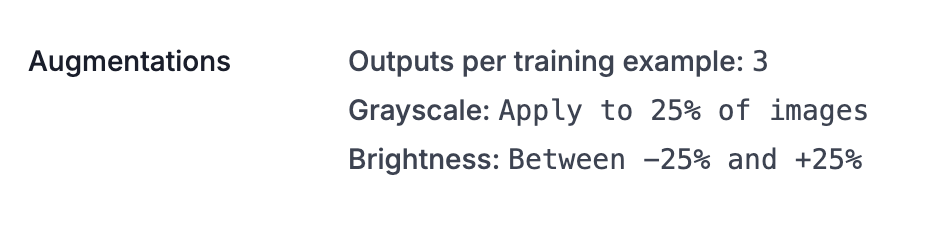

## **1.4 Dataset Analysis**

The following graph shows a rough breakdown of how many images are in the dataset for each of the 10 tags. As we would expect, partial views of Building K are by far the most common (567 images), since views of the building in its entirety from campus are rare. There are many more morning shots (421 images) than there are dusk shots (176 images), since the latter were very difficult to annotate and tag properly. As one would expect, there are far more images of the front of the building (220 images) than there are of the back (86 images), and only a handful of images of Building K from strange angles (rotated images: 20 images). This last point is particularly relevant for future work where collecting more images of Building K from full views (10 images) and from rotated angles would be ideal.

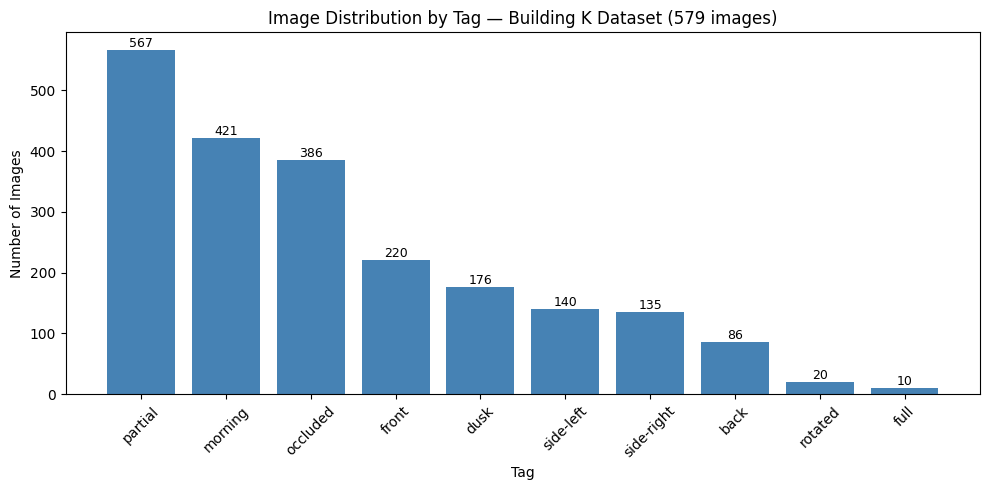

In [ ]:
import matplotlib.pyplot as plt

tags = {
    "partial": 567,
    "morning": 421,
    "occluded": 386,
    "front": 220,
    "dusk": 176,
    "side-left": 140,
    "side-right": 135,
    "back": 86,
    "rotated": 20,
    "full": 10
}

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(tags.keys(), tags.values(), color="steelblue")
ax.set_title("Image Distribution by Tag — Building K Dataset (579 images)")
ax.set_xlabel("Tag")
ax.set_ylabel("Number of Images")
ax.tick_params(axis='x', rotation=45)
for bar, val in zip(bars, tags.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            str(val), ha='center', fontsize=9)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/COMP4010_finalprj/building_K/tag_distribution.png", dpi=150)
plt.show()

# **2. Model Training**

To systematically assess the impact of two different improvements on object segmentation - the newly annotated dataset Version 2 and the hyperparameter search space of YOLOv8 - we train and evaluate four different models. All four models were trained using the improved dataset and then were evaluated on a held-out set of 87 images (the validation set) at the default confidence threshold for YOLOv8 of 0.25. This confidence threshold is the standard used throughout the literature to report results, and thus our results are directly comparable. We also performed a confidence threshold analysis for the model with the best performance. Details of this analysis can be found in Sub-Section 2.3.

**Evaluation Metrics:** Two important evaluation metrics are used for the benchmark: Recall and mAP@50. Recall measures the ratio of detected to actual instances of buildings for a given image. In other words, it answers the question of how many buildings a model is able to detect, while counting correctly detected instances multiple times. Its converse, missing instances, results in very poor performance. mAP@50 (mean Average Precision at 0.5 IoU threshold) is a more general metric, used as a benchmark for various types of segmentation tasks. In the Building Detection context, it is also used as the primary metric to quantify both the detection accuracy and the segmentation quality of the predicted masks. A detection is considered correct when its IoU with the ground truth mask is greater than 0.5. Precision, i.e. the ratio of correct to total detections, is reported as well. However, since false positives for the context of Building Detection (i.e. a system incorrectly detects something to be Building K) have minimal penalty, while false negatives (i.e. missing a building that is clearly present in the images for a campus navigation or AR system which fails to recognize the building the system is currently looking for) result in a completely failed system, higher priority is placed on Recall and mAP@50 metrics.

## **2.1 Baseline Model (YOLOv8 Nano)**
The baseline model was set up to match Milestone 1, in terms of configuration to training a YOLOv8 nano for segmentation over 50 epochs with the default hyper-parameters. The main difference here is that the model was trained on the expanded dataset rather than the initial small set of images. This means we can see the effects of the new data prior to any modification to the model or training regime.

In [ ]:
!pip install ultralytics -q

from ultralytics import YOLO

model = YOLO("yolov8n-seg.pt")

model.train(
    data=data_yaml,
    epochs=50,
    imgsz=640
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 81.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/VinUni_buildings_dataset-2/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None,

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7faf25a15790>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041, 

In [ ]:
metrics = model.val()

precision = metrics.results_dict['metrics/precision(B)']
recall    = metrics.results_dict['metrics/recall(B)']
map50     = metrics.results_dict['metrics/mAP50(B)']
map5095   = metrics.results_dict['metrics/mAP50-95(B)']

print("===== MODEL EVALUATION RESULTS =====\n")
print(f"Precision        : {precision:.4f}")
print(f"Recall           : {recall:.4f}")
print(f"mAP@50           : {map50:.4f}")
print(f"mAP@50-95        : {map5095:.4f}")

print("\n===== INTERPRETATION =====\n")

if map50 >= 0.9:
    print("Excellent detection performance.")
elif map50 >= 0.8:
    print("Very good detection performance.")
elif map50 >= 0.7:
    print("Good detection performance.")
else:
    print("Model performance can still be improved.")

print("\nHigher precision means fewer false detections.")
print("Higher recall means fewer missed buildings.")

Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2399.2±643.7 MB/s, size: 65.6 KB)
val: Scanning /content/VinUni_buildings_dataset-2/valid/labels.cache... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87 33.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.5it/s 2.4s
                   all         87        220      0.912      0.613      0.683      0.578      0.926      0.622       0.69      0.567
Speed: 3.3ms preprocess, 3.0ms inference, 0.0ms loss, 3.2ms postprocess per image
Results saved to /content/runs/segment/val-2
===== MODEL EVALUATION RESULTS =====

Precision        : 0.9121
Recall           : 0.6128
mAP@50           : 0.6832
mAP@50-95        : 0.5776

===== INTERPRETATION =====

Model performance can still be improved.

Higher precision means fewer false detecti

Baseline’s precision, recall, and mAP@50 scores were 0.9121, 0.6128 and 0.6832, respectively. Note that a big jump in terms of recall was achieved in this milestone compared to Milestone 1 scores of 0.5028 for recall and 0.5924 for mAP@50. Importantly, this huge jump in recall ( +11% ) was solely due to the diverse data-set used in training the same model architecture with the same configuration as Milestone 1.

## **2.2 Model V2 — YOLOv8 Small with Tuned Hyperparameters**
From the baseline, we can see that there is still room to improve the model architecture and training configuration. To address this, we made two changes. First, we swapped from YOLOv8 nano to YOLOv8 small (yolov8s-seg) – YOLOv8 small has many more parameters than YOLOv8 nano, and therefore is able to learn to recognize many more features of the appearances of buildings. Secondly, we also changed some of the hyperparameters to be tuned for the small amount of data that we have. The learning rate was set to 0.005 to not learn too much from the features that were pre-trained on a very different dataset. We also added some rotation (up to ±15°) and mixup (0.1) to increase generalization to new data. Finally, we added early stopping (patience 15) to prevent overfitting, and a fixed seed (42) for reproducibility.

In [ ]:
from ultralytics import YOLO

model_v2 = YOLO("yolov8s-seg.pt")

model_v2.train(
    data=data_yaml,
    epochs=100,
    patience=15,
    imgsz=640,
    batch=16,
    seed=42,
    lr0=0.005,
    degrees=15.0,
    mixup=0.1,
    project="/content/drive/MyDrive/COMP4010_finalprj/building_K/runs",
    name="yolov8s_v2"
)

Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/VinUni_buildings_dataset-2/data.yaml, degrees=15.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_v2-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, o

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7faf2a31ac60>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041, 

In [ ]:
metrics_v2 = model_v2.val()

precision = metrics_v2.results_dict['metrics/precision(B)']
recall    = metrics_v2.results_dict['metrics/recall(B)']
map50     = metrics_v2.results_dict['metrics/mAP50(B)']
map5095   = metrics_v2.results_dict['metrics/mAP50-95(B)']

print("===== MODEL EVALUATION RESULTS =====\n")
print(f"Precision        : {precision:.4f}")
print(f"Recall           : {recall:.4f}")
print(f"mAP@50           : {map50:.4f}")
print(f"mAP@50-95        : {map5095:.4f}")

print("\n===== INTERPRETATION =====\n")

if map50 >= 0.9:
    print("Excellent detection performance.")
elif map50 >= 0.8:
    print("Very good detection performance.")
elif map50 >= 0.7:
    print("Good detection performance.")
else:
    print("Model performance can still be improved.")

print("\nHigher precision means fewer false detections.")
print("Higher recall means fewer missed buildings.")

Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLOv8s-seg summary (fused): 86 layers, 11,779,987 parameters, 0 gradients, 39.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1475.0±661.3 MB/s, size: 66.1 KB)
val: Scanning /content/VinUni_buildings_dataset-2/valid/labels.cache... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87 33.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.5it/s 2.4s
                   all         87        220      0.815       0.65      0.697       0.59      0.801      0.677      0.695      0.586
Speed: 3.0ms preprocess, 7.3ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to /content/runs/segment/val-3
===== MODEL EVALUATION RESULTS =====

Precision        : 0.8151
Recall           : 0.6500
mAP@50           : 0.6973
mAP@50-95        : 0.5904

===== INTERPRETATION ===

The best performing model so far was V2 which scored the highest mAP@50 of 0.6973 and highest recall of 0.6500. The larger architecture with the more tuned hyperparameters led to better generalization. However, precision fell to 0.8151 which was worse than the baseline. It can be seen mixup is making the model less conservative in its detections, but also lowers precision.

## **2.3 Confidence Threshold Analysis on V2**
To gain more insight into the precision-recall tradeoff of V2, the model has been tested at four different confidence thresholds. By increasing the threshold, the model will only report the objects it is very confident about, which in turn will increase the precision and decrease the recall.

In [ ]:
for conf in [0.25, 0.35, 0.5, 0.6]:
    m = model_v2.val(conf=conf, verbose=False)
    p = m.results_dict['metrics/precision(B)']
    r = m.results_dict['metrics/recall(B)']
    print(f"conf={conf:.2f} | Precision: {p:.4f} | Recall: {r:.4f}")

Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1813.2±506.9 MB/s, size: 60.6 KB)
val: Scanning /content/VinUni_buildings_dataset-2/valid/labels.cache... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87 33.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.4it/s 2.5s
                   all         87        220      0.815       0.65      0.659      0.571      0.801      0.677      0.668      0.574
Speed: 3.1ms preprocess, 5.4ms inference, 0.0ms loss, 5.6ms postprocess per image
Results saved to /content/runs/segment/val-12
conf=0.25 | Precision: 0.8151 | Recall: 0.6500
Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 855.8±155.4 MB/s, size: 65.7 KB)
val: Scanning /content/VinUni_buildings_

At conf=0.60, precision recovers to 0.9041 while recall only drops modestly to 0.6000. This analysis informed the design of V3 — rather than simply raising the threshold post-hoc, we investigated whether removing mixup during training could improve precision while preserving recall.

## **2.4 Model V3 — No Mixup**
V3 is similar to V2, except that mixup is disabled (mixup=0.0) and the learning rate is increased to 0.008. Our hypothesis here is that mixup, which mix and matches images from the training set in pairs, introduces too much confusion in a single-class setup.

In [ ]:
model_v3 = YOLO("yolov8s-seg.pt")

model_v3.train(
    data=data_yaml,
    epochs=100,
    patience=15,
    imgsz=640,
    batch=16,
    seed=42,
    lr0=0.008,
    degrees=15.0,
    mixup=0.0,
    project="/content/drive/MyDrive/COMP4010_finalprj/building_K/runs",
    name="yolov8s_v3"
)

Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/VinUni_buildings_dataset-2/data.yaml, degrees=15.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.008, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_v3-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, o

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7faf29f55790>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041, 

In [ ]:
metrics_v3 = model_v3.val()

precision = metrics_v3.results_dict['metrics/precision(B)']
recall    = metrics_v3.results_dict['metrics/recall(B)']
map50     = metrics_v3.results_dict['metrics/mAP50(B)']
map5095   = metrics_v3.results_dict['metrics/mAP50-95(B)']

print("===== MODEL EVALUATION RESULTS =====\n")
print(f"Precision        : {precision:.4f}")
print(f"Recall           : {recall:.4f}")
print(f"mAP@50           : {map50:.4f}")
print(f"mAP@50-95        : {map5095:.4f}")

print("\n===== INTERPRETATION =====\n")

if map50 >= 0.9:
    print("Excellent detection performance.")
elif map50 >= 0.8:
    print("Very good detection performance.")
elif map50 >= 0.7:
    print("Good detection performance.")
else:
    print("Model performance can still be improved.")

print("\nHigher precision means fewer false detections.")
print("Higher recall means fewer missed buildings.")

Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2043.7±589.0 MB/s, size: 60.6 KB)
val: Scanning /content/VinUni_buildings_dataset-2/valid/labels.cache... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87 36.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.4it/s 2.5s
                   all         87        220      0.959      0.595      0.676      0.566      0.848      0.641      0.682      0.576
Speed: 1.1ms preprocess, 6.4ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /content/runs/segment/val-10
===== MODEL EVALUATION RESULTS =====

Precision        : 0.9588
Recall           : 0.5955
mAP@50           : 0.6759
mAP@50-95        : 0.5655

===== INTERPRETATION =====

Model performance can still be improved.

Higher precision means fewer false detect

Removing mixup successfully recovered precision to 0.9588 — the highest of all models — confirming that mixup was a contributing factor to V2's lower precision. However, mAP@50 dropped to 0.6759 and recall fell to 0.5955, both below V2. V3 is a more conservative detector: it almost never produces false detections, making it preferable for real-time video stream applications where false positives are visually disruptive.

## **2.5 Model V4 — Reduced Mixup**
In V3, we observed that removing mixup completely resulted in too-aggressive degradation in terms of recall and mAP. Our new model V4 investigates a middle ground, a reduced mixup of 0.05, i.e., trying to keep some of the generalization power of the full mixup, and at the same time trying to come closer to the precision of V2.

In [ ]:
model_v4 = YOLO("yolov8s-seg.pt")

model_v4.train(
    data=data_yaml,
    epochs=100,
    patience=15,
    imgsz=640,
    batch=16,
    seed=42,
    lr0=0.008,
    degrees=15.0,
    mixup=0.05,
    project="/content/drive/MyDrive/COMP4010_finalprj/building_K/runs",
    name="yolov8s_v4"
)

Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/VinUni_buildings_dataset-2/data.yaml, degrees=15.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.008, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_v4-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, 

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7faf2a10d220>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041, 

In [ ]:
metrics_v4 = model_v4.val()

precision = metrics_v4.results_dict['metrics/precision(B)']
recall    = metrics_v4.results_dict['metrics/recall(B)']
map50     = metrics_v4.results_dict['metrics/mAP50(B)']
map5095   = metrics_v4.results_dict['metrics/mAP50-95(B)']

print("===== MODEL V4 EVALUATION RESULTS =====\n")
print(f"Precision        : {precision:.4f}")
print(f"Recall           : {recall:.4f}")
print(f"mAP@50           : {map50:.4f}")
print(f"mAP@50-95        : {map5095:.4f}")

print("\n===== INTERPRETATION =====\n")

if map50 >= 0.9:
    print("Excellent detection performance.")
elif map50 >= 0.8:
    print("Very good detection performance.")
elif map50 >= 0.7:
    print("Good detection performance.")
else:
    print("Model performance can still be improved.")

print("\nHigher precision means fewer false detections.")
print("Higher recall means fewer missed buildings.")

Ultralytics 8.4.61 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLOv8s-seg summary (fused): 86 layers, 11,779,987 parameters, 0 gradients, 39.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1983.4±335.6 MB/s, size: 66.1 KB)
val: Scanning /content/VinUni_buildings_dataset-2/valid/labels.cache... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87 33.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.3it/s 2.7s
                   all         87        220      0.833      0.636      0.671      0.558       0.89      0.605      0.673      0.569
Speed: 3.3ms preprocess, 6.0ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/runs/segment/val-11
===== MODEL V4 EVALUATION RESULTS =====

Precision        : 0.8335
Recall           : 0.6364
mAP@50           : 0.6715
mAP@50-95        : 0.5575

===== INTERPRETATION

V4 achieved a precision of 0.8335, recall of 0.6364, and mAP@50 of 0.6715 — sitting between V2 and V3 as expected. However, it offers no clear advantage over either model: it is less precise than V3 and has lower mAP and recall than V2. This confirms that V2 remains the best general-purpose model and V3 the best choice for precision-sensitive deployment.

# **3. Results and Model Selection**

| Model | Precision | Recall | mAP@50 | mAP@50-95 |
|---|---|---|---|---|
| Baseline (YOLOv8n) | 0.9121 | 0.6128 | 0.6832 | 0.5776 |
| V2 (YOLOv8s, mixup=0.1) | 0.8151 | 0.6500 | **0.6973** | **0.5904** |
| V3 (YOLOv8s, no mixup) | **0.9588** | 0.5955 | 0.6759 | 0.5655 |
| V4 (YOLOv8s, mixup=0.05) | 0.8335 | 0.6364 | 0.6715 | 0.5575 |

V2 is the best model for detection quality overall with the highest mAP@50 and the highest recall. V3 is the preferred model for real-time video processing as it significantly outperforms the others in terms of precision. Both models are now saved on Google Drive for later use.

In [ ]:
import shutil, os

MODELS_DIR = "/content/drive/MyDrive/COMP4010_finalprj/building_K/models"
os.makedirs(MODELS_DIR, exist_ok=True)

# Save V2 best weights
shutil.copy(
    "/content/drive/MyDrive/COMP4010_finalprj/building_K/runs/yolov8s_v2/weights/best.pt",
    os.path.join(MODELS_DIR, "building_k_v2_best.pt")
)

# Save V3 best weights
shutil.copy(
    "/content/drive/MyDrive/COMP4010_finalprj/building_K/runs/yolov8s_v3/weights/best.pt",
    os.path.join(MODELS_DIR, "building_k_v3_best.pt")
)

print("Saved:")
for f in os.listdir(MODELS_DIR):
    size = os.path.getsize(os.path.join(MODELS_DIR, f)) / (1024*1024)
    print(f"  {f}  ({size:.1f} MB)")

Saved:
  building_k_v2_best.pt  (22.8 MB)
  building_k_v3_best.pt  (22.8 MB)


# **4. Video Stream Demo**
To demonstrate real-world applicability, both V2 and V3 are applied to a raw video of Building K. V2 detections are shown with a red mask and V3 with a blue mask, allowing direct visual comparison of the two models' behaviour on the same footage.

- Using V2 model: https://drive.google.com/file/d/1RvbAEtx1a8XP2_pgvXROdm_nG6WxM3GZ/view?usp=sharing

- Using V3 model: https://drive.google.com/file/d/1Lz7zFmx0DQHR2OiZdOhRpqSU6RtUlXEC/view?usp=drive_link

In [ ]:
import os
import cv2
import numpy as np
from ultralytics import YOLO

VIDEO_PATH = "/content/drive/MyDrive/COMP4010_finalprj/building_K/building_k_raw/new2.mp4"
OUTPUT_DIR = "/content/drive/MyDrive/COMP4010_finalprj/building_K/video_predictions"
os.makedirs(OUTPUT_DIR, exist_ok=True)

model_v2 = YOLO("/content/drive/MyDrive/COMP4010_finalprj/building_K/models/building_k_v2_best.pt")
model_v3 = YOLO("/content/drive/MyDrive/COMP4010_finalprj/building_K/models/building_k_v3_best.pt")

# BGR color format: Red=(0,0,255), Blue=(255,0,0)
configs = [
    (model_v2, "Model V2", (0, 0, 255),   "new2_v2.mp4"),
    (model_v3, "Model V3", (255, 0, 0),   "new2_v3.mp4"),
]

cap    = cv2.VideoCapture(VIDEO_PATH)
fps    = cap.get(cv2.CAP_PROP_FPS)
width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total  = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()

print(f"Video: new2.mp4 — {total} frames at {fps:.0f}fps\n")

for model, label, color, out_name in configs:
    out_path = os.path.join(OUTPUT_DIR, out_name)
    writer   = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))

    print(f"Running {label}...", end=" ", flush=True)

    for fi, result in enumerate(model(VIDEO_PATH, stream=True, conf=0.25, verbose=False), 1):
        frame = result.orig_img.copy()

        # Draw colored segmentation mask
        if result.masks is not None:
            for mask in result.masks.data:
                mask_np     = mask.cpu().numpy()
                mask_resized = cv2.resize(mask_np, (width, height))
                mask_bool   = mask_resized > 0.5

                # Colored fill with transparency
                overlay = frame.copy()
                overlay[mask_bool] = color
                frame = cv2.addWeighted(frame, 0.55, overlay, 0.45, 0)

                # Outline contour
                contours, _ = cv2.findContours(
                    (mask_resized * 255).astype(np.uint8),
                    cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
                )
                cv2.drawContours(frame, contours, -1, color, 3)

        # Confidence score
        if result.boxes is not None and len(result.boxes) > 0:
            conf = result.boxes.conf[0].item()
            cv2.putText(frame, f"building_k  {conf:.2f}", (20, 80),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.2, color, 2, cv2.LINE_AA)

        # Model label in top-left
        cv2.putText(frame, label, (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.2, color, 2, cv2.LINE_AA)

        writer.write(frame)
        if fi % 200 == 0:
            print(f"{fi/total*100:.0f}%...", end=" ", flush=True)

    writer.release()
    print(f"done ✓  →  {out_name}")

print(f"\nSaved to: {OUTPUT_DIR}")

Video: new2.mp4 — 2277 frames at 59fps

Running Model V2... 9%... 18%... 26%... 35%... 44%... 53%... 61%... 70%... 79%... 88%... 97%... done ✓  →  new2_v2.mp4
Running Model V3... 9%... 18%... 26%... 35%... 44%... 53%... 61%... 70%... 79%... 88%... 97%... done ✓  →  new2_v3.mp4

Saved to: /content/drive/MyDrive/COMP4010_finalprj/building_K/video_predictions


# **5. Conclusion and Future Work**

The final milestone showed that for building segmentation, dataset diversity is the single most important factor for improving performance. By simply adding images of buildings at different times of day, from different viewpoints, from different distances and with partial occlusion, the recall of the unaltered model went up from 50.28% to 65.00%. Then, by improving the model and doing hyperparameter search, the best model V2 reached a mAP@50 of 0.6973.

Future work includes an per-category recall analysis on the conditions in which the model fails according to the Roboflow image tags. Additional data is also required, particularly with different lighting conditions, and more recordings. The model is to be scaled up to train on detection of other buildings on campus, in a multi-class segmentation setting, with the goal of deploying it for real time inference on video streams to be used in Augmented Reality, or in a campus navigation system.